<a href="https://colab.research.google.com/github/LiaIssakov/Portfolio_2025/blob/main/orthonormal_bases_and_change_of_basis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Orthonormal basis and change of basis

## We will focus things that are most important for data science:
- standard basis
- other orthonormal basis
- change of basis between the two above
- the concept of partial basis



# Recap: basis vectors

When we talked about vectors, it was implied that we interpret them as vectors in the *standard basis*. In 2D it's just $e_1 = (1,0)^T$, $e_2 = (0,1)^T$. So a vector $(3,5)$ can be interpreted as a mix of the basis vectors: $3e_1 + 5e_2$.

> Say $B$ is a basis of $\mathbb{R}^n$. How many vector are there in $B$? What's the dimension of each of these vectors?

We can think about a different (ordered) basis $B = (b_1, b_2)$. Then point $(3,5)$ in this basis would be interpreted as $3b_1 + 5b_2$. To emphasize the basis we work with, we could say $(3,5)_{(B)}$. But when we program we have to keep in mind which basis we work with.

> Intuitively, we can think about different bases as different coordinates system.

# Time for my silly story with a river and gps! (In class exclusive.)

# Important conventions
We will often represent basis as a matrix. By convention we will store each basis vector of a **column** of our matrix. So if we think about an basis vectors $b_1 = (1,2),\ b_2 = (3,4)$, we will represent them as a matrix \begin{bmatrix}
1 & 3 \\
2 & 4
\end{bmatrix}

> This is also the convension used by numpy. In particular, it will be crucial when we start working with SVD.

> On the other hand, sklearn tends to assume that each row of an array is a data-element. So it's easy to get things mixed up!

#Orthonormality and orthonormal bases

It sounds scary, but working with orthonormal bases will simplify things a lot.

In an orthonormal set of vectors, the vectors are:
- normalized (i.e. have unit norm/length, alternatively the dot product of each vector with itself is 1)
- pairwise orthogonal (i.e. perpendicular, meaning the dot product of any two different vectors is 0.)

In other words, if $M$ is orthonormal, $M^TM = I$, namely the identity matrix.
> Think about what $M^TM$ does!


We say a **basis is orthonormal** if its elements form an orthonormal set of vectors.

# Why orthonormal bases

- They simplify things (both computations and interpretation)
- They will be very useful for us (SVD, random projections)...

# "Truncated basis"

- Later we will choose a small number of basis elements to represent our data

In [ ]:
from ipywidgets import *
import ipywidgets as widgets

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as lines

# Finding a useful basis

> This foreshadows SVD which we'll look into soon. Still the visualization should make sense, even if the code is criptic for now.

## Some useful functions

In [ ]:
#@title
# I just plot a point. No need to look inside.
def draw_point(v, txt = "", color = 'b'):
  plt.scatter(*v, c = color)
  plt.axis('equal') # otherwise it looks ugly
  if txt:
    plt.text(*(v + np.array((0.01, 0))), txt, c = 'gray', fontsize = 20)

# I plot a nice arrow between v,t. No need to look inside, just try me out.
def draw_arrow(v, t, txt="", color='g', bold=False):
  '''I plot a nice arrow between v,t. No need to look inside, just try me out.'''
  v = np.asarray(v)
  t = np.asarray(t)
  dxy = t-v
  plt.scatter(*v, c='k')
  plt.scatter(*(v+dxy), c='k', alpha=0)
  head_width = np.linalg.norm(dxy)/20. * [1,2.5][bold]
  line_width = 1 if not bold else 2
  plt.arrow(*v, *dxy, length_includes_head=True,
            head_width=head_width, linewidth=line_width, color=color)
  if txt:
    plt.text(*(v+dxy/2. + (0.01, 0)), txt, c='gray', fontsize=20)
  plt.axis('equal') # otherwise it looks ugly

In [ ]:
X = (np.random.randn(100, 2) * (0.2, 1))@[[0.7, 0.5],[-0.7, 1]]

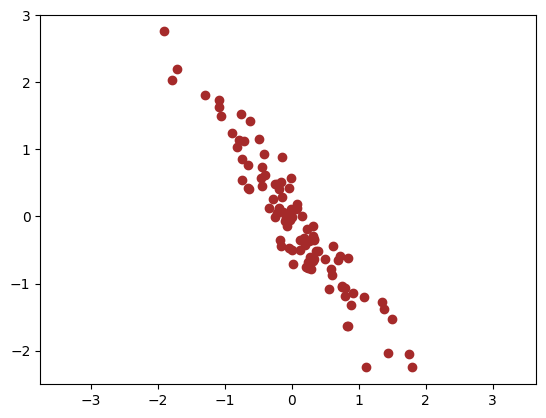

In [ ]:
plt.scatter(*X.T, c='brown');
plt.axis('equal');

## Some code, move along

In [ ]:
# Just a convenient function to play with matrices of arbitrary size
from scipy.linalg import diagsvd

M = X.T # !
U, S, Vt = np.linalg.svd(M, full_matrices=True)

S = diagsvd(S, *M.shape) # nicely pads the matrix with zeros
print('shapes:', M.shape, U.shape, S.shape, Vt.shape)

shapes: (2, 100) (2, 2) (2, 100) (100, 100)


In [ ]:
assert np.allclose(U@S@Vt, M) # M = USV^T, so it actually works!

# Finding the basis

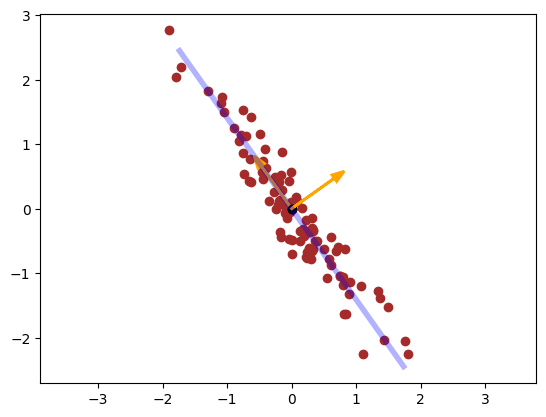

In [ ]:
plt.scatter(*X.T, c='brown')
v = U.T[0]
c = 3; plt.plot([-c*v[0], +c*v[0]], [-c*v[1], +c*v[1]], c='blue', alpha=0.3, lw=4)

for basis_vector in U.T:
  draw_arrow((0,0), basis_vector, bold=True, color='orange')

plt.axis('equal');

# Task 1:

Imagine you are givien a vector in some basis $B$. How can you express this vector in the standard basis? Implement function *express_point_in_some_basis_as_standard* and test it a little.

> In the code below, I name the basis B as 'OLD', to remind you that $p$ refers to ('is expressed in') this basis.

> Tip: try to think about matrices. Doing a simple 2x2 example may be helpful.

> Important: If you did it, what'd happen if p would be more than 1 vector? Say a 2D array with n vectors as rows? Does it work right away? If not, How can you use the function you implemented so that it works?

In [ ]:
def express_point_in_some_basis_as_standard(p, OLD):
  '''Takes p expressed in its 'OLD' basis
  (so p tells us to how mix the basis vectors
  which are columns of OLD).
  Return this point p expressed in the standard basis'''
  return p # FIX ME!

# Task 2:

Now try to think about going in the other -- more interesting -- direction. We have a vector in the standard basis, but want to express it in another **orthonormal** basis.

a) Implement function *express_point_in_new_basis* below.

> You may recall the standard general solution. But I'd like you to try to understand the situation specifically for the orthonormal basis!

> Tip: remember our geometric excercise with dot products?

b) To test it, play with the interactive plot below which uses your implementation. Does everything look good? Can you interpret it?

> Extra: How would *express_point_in_new_basis* have to change if $B$ is **not** orthonormal?

In [ ]:
def express_point_in_new_basis(p, NEW):
  '''Now we get p expressed in the standard basis and want to
  express it in a NEW *orthonormal* basis'''
  return p  # FIX ME!

## Implementation of the visualization (not crucial)

In [ ]:
#@title
import matplotlib.pyplot as plt
import matplotlib.lines as lines
import matplotlib.patches as pt

sl = lambda x : widgets.FloatSlider(value=x, min = -5., max = 5., step = 0.1)

R = np.vstack(([0,0], [0,1], [1,1], [1,0], [0,0]))

def plot_grid(A, **kw):
  k = 13
  q = 1e6
  S = np.array([(-q, x) for x in np.arange(-k,k,1)])
  E = S + np.array((2*q, 0))
  S = (A @ S.T).T
  E = (A @ E.T).T
  [plt.gca().add_artist(lines.Line2D([a[0],b[0]], [a[1], b[1]], alpha = kw['alpha'], color = kw['color'])) for a,b in zip(S,E)]

def plot_basis(A, **kw):
  draw_arrow([0,0],A.T[0], color = kw['color'])
  draw_arrow([0,0], A.T[1], color = kw['color'])
  return

  S = np.zeros((2,2))
  E = np.eye(2)
  S = (A @ S.T).T
  E = (A @ E.T).T
  [plt.gca().add_artist(lines.Line2D([a[0],b[0]], [a[1], b[1]], alpha = kw['alpha'], color = kw['color'], lw = 3)) for a,b in zip(S,E)]

def vis_change(B, A, p, grid = True, grid_new = True):
  plt.figure(figsize = (14, 14))

  p = np.array(p)

  print(f'point p in original basis = {p}')
  print(f'original basis vectors: {B.T[0]}, {B.T[1]}')
  draw_point(p, txt = f"p = {np.round(p,3)} (in the standard basis!)")

  draw_arrow([0,0], A.T[0], color = 'blue')
  draw_arrow([0,0], A.T[1], color = 'blue')

  plt.scatter(*A)
  plt.scatter(0,0)

  x = express_point_in_new_basis(p, A)
  p2 = express_point_in_some_basis_as_standard(x, A) # change p to x

  print(f'new basis vectors: {A.T[0]}, {A.T[1]}')
  print(f'your function from task 2 says that: point {np.round(p, 3)} in new basis is {np.round(x,3)}')

  print(f'your function from task 1 says that: point {np.round(x,3)} in standard basis is {np.round(p2,3)}')

  draw_point(x, txt = f"I am {np.round(x,3)}, you can technically plot me\nbut I represent coordinates in another (non-standard) basis!")

  u = A.T[0] * x[0]
  v = A.T[1] * x[1]

  ORIGIN = (0,0)
  draw_arrow(ORIGIN, u, color = 'black', txt = f'{x[0]:.3f}')
  draw_arrow(ORIGIN, v, color = 'black', txt = f'{x[1]:.3f}')

  draw_arrow(p, u)
  draw_arrow(p, v)

  draw_point(u)
  draw_point(v)

  if grid:
    plot_grid(B, alpha = 0.1, color = 'red')
    plot_grid(B@[[0,-1],[1,0]], alpha = 0.1, color = 'red')

  if grid_new:
    plot_grid(A, alpha = 0.2, color = 'blue')
    plot_grid(A@[[0,-1],[1,0]], alpha = 0.2, color = 'blue')

  plot_basis(A, alpha = 1, color = 'blue')
  plot_basis(B, alpha = 1, color = 'red')

  plt.axis('equal')
  plt.show()

In [ ]:
#@title

def gs(A):
  A[0] /= np.linalg.norm(A[0])
  A[1] -= A[1]@A[0]*A[0]
  A[1] /= np.linalg.norm(A[1])
  return A


def go(grid, grid_new, orthonormalize, a,b, p1, p2):
  e=1.;f=0.;g=0.;h=1.
  c,d = 0.,1.
  B = np.array([[e,f],[g,h]])
  A = np.array([[a,b],[c,d]])

  if orthonormalize:
    A = gs(A)
    B = gs(B)
    #print("our basis matrix:\n", A)

  A = A.T
  B = B.T

  vis_change(B, A, (p1,p2), grid, grid_new)

# What we should get

This is what the visualization below should show if you implement the 2 functions correctly

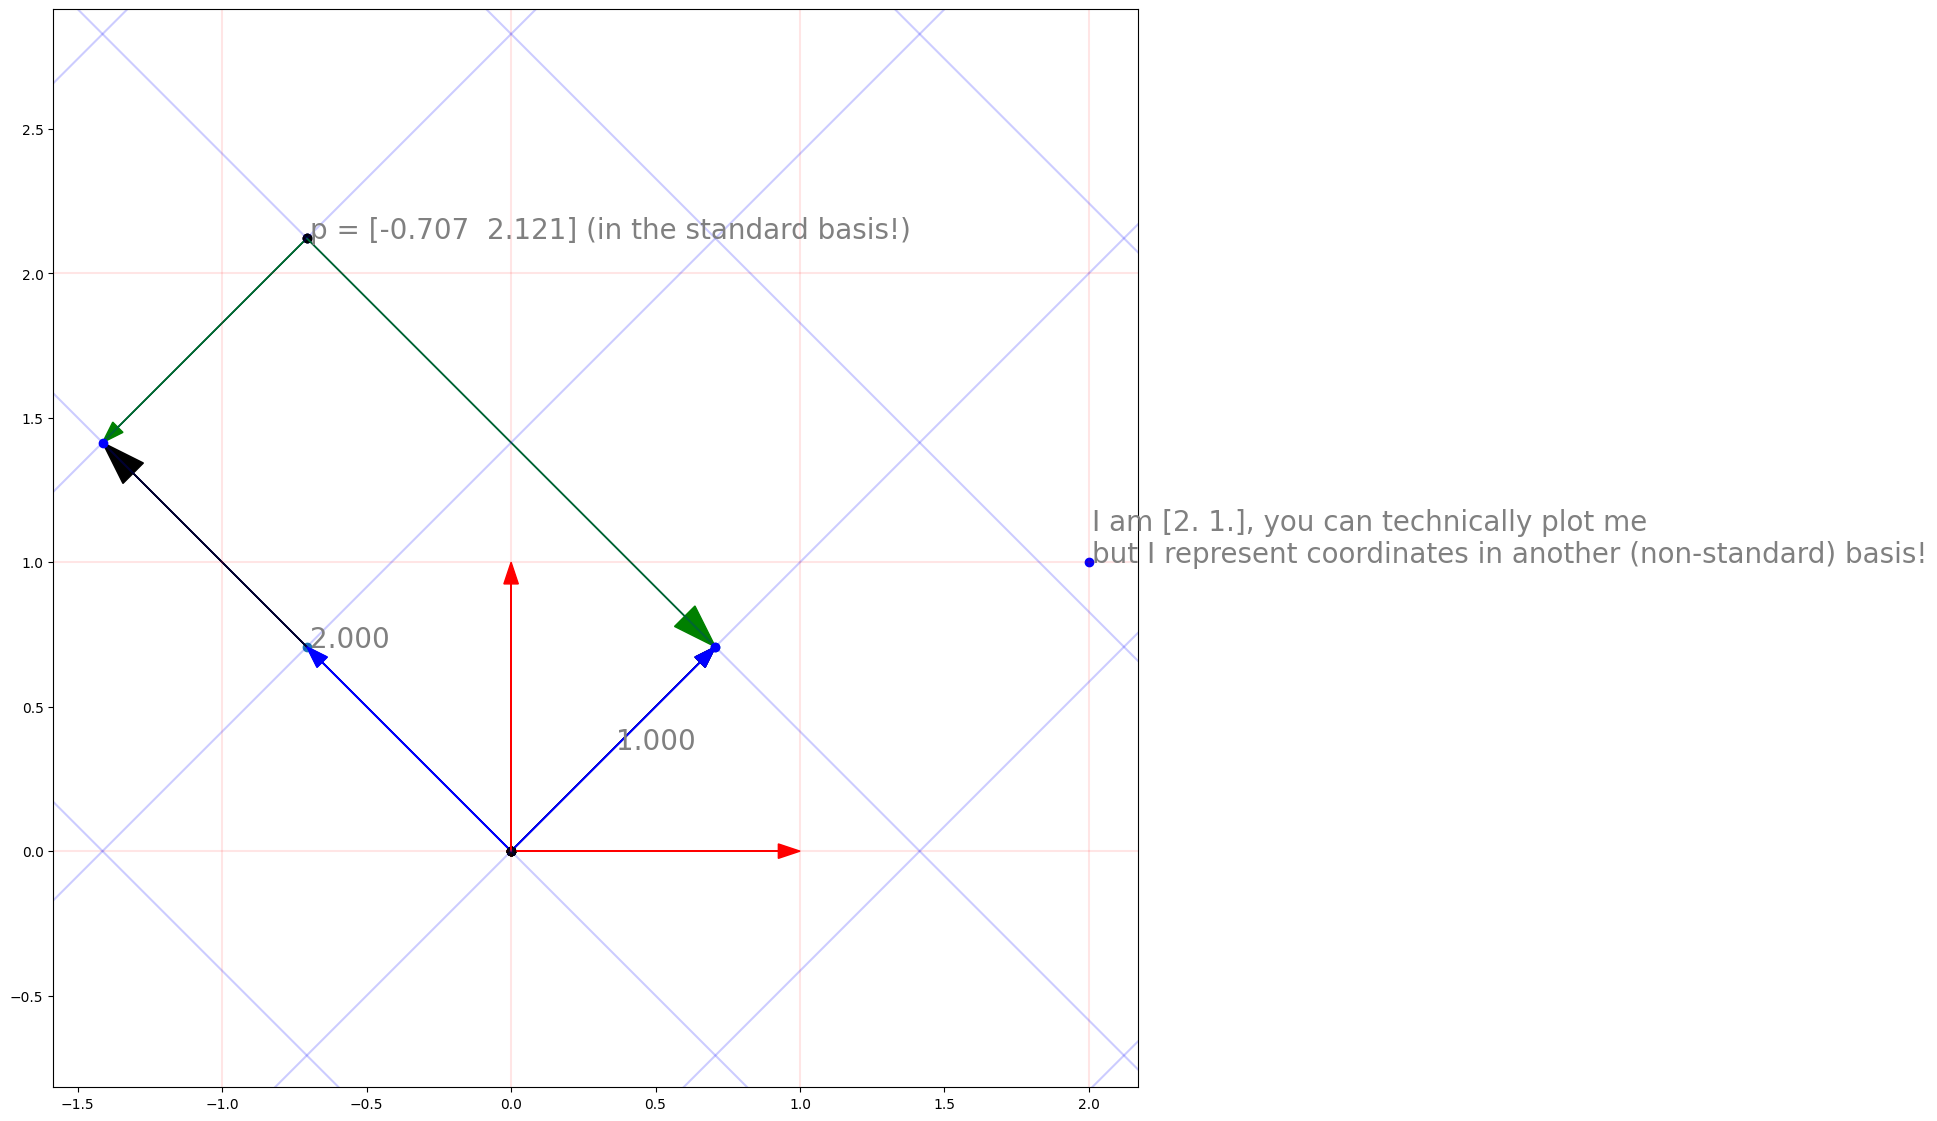

# Play with me! (after implementing the two crucial functions)

The idea is to see how your two function work. You'll control the NEW basis and point $p$ with sliders. This scode uses the functions you implemented above. If they're okay everything should look nice and understandable.

Parameters $a,b$ set **one** of the new basis vectors to be $(a,b)$. The other is just computed to be a unit vector orthogonal to it.

$p_1, p_2$ control the coordinates of the point $p=(p_1, p_2)$ that we want to express in the new basis.


In [ ]:
s2 = np.sqrt(2)

interactive_plot = interactive(go,
                               grid=True, grid_new=True,
                               orthonormalize=True,
                               a=sl(-s2/2), b=sl(s2/2),
                               p1=sl(-s2/2), p2=sl(3*s2/2))

interactive_plot.layout.height = '1200px'
interactive_plot.layout.width = '1200px'
HBox([interactive_plot])

# Optional:

If you're done -- can you think *why* expressing vectors in a new basis could be useful in practice?

Also what's the relationship between the two functions you implemented?